In [9]:
import os

os.chdir(r"C:\Users\Aquib\Desktop\SegFormer_Cityscapes_Project")
print(os.getcwd())

C:\Users\Aquib\Desktop\SegFormer_Cityscapes_Project


In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

from transformers import SegformerForSemanticSegmentation

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

DATA_ROOT = r"C:\Users\Aquib\Desktop\SegFormer_Cityscapes_Project\Data\cityscapes"

image_transform = transforms.Compose([
    transforms.Resize((512, 512)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

mask_transform = transforms.Compose([
    transforms.Resize(
        (512, 512),
        interpolation=transforms.InterpolationMode.NEAREST
    ),
    transforms.PILToTensor()
])

Device: cuda


In [3]:
class CityscapesDataset(Dataset):

    def __init__(self, root, split="train",
                 image_transform=None,
                 mask_transform=None):

        self.image_dir = os.path.join(
            root, "leftImg8bit", split
        )

        self.label_dir = os.path.join(
            root, "gtFine", split
        )

        self.image_transform = image_transform
        self.mask_transform = mask_transform

        self.images = []

        for city in os.listdir(self.image_dir):

            city_path = os.path.join(
                self.image_dir, city
            )

            for img in os.listdir(city_path):

                if img.endswith("_leftImg8bit.png"):

                    self.images.append((city, img))

    def __len__(self):

        return len(self.images)

    def __getitem__(self, idx):

        city, img_name = self.images[idx]

        img_path = os.path.join(
            self.image_dir,
            city,
            img_name
        )

        label_name = img_name.replace(
            "_leftImg8bit.png",
            "_gtFine_labelIds.png"
        )

        label_path = os.path.join(
            self.label_dir,
            city,
            label_name
        )

        image = Image.open(img_path).convert("RGB")

        mask = Image.open(label_path)

        mask = np.array(mask)

        id_map = {
            7:0,
            8:1,
            11:2,
            12:3,
            13:4,
            17:5,
            19:6,
            20:7,
            21:8,
            22:9,
            23:10,
            24:11,
            25:12,
            26:13,
            27:14,
            28:15,
            31:16,
            32:17,
            33:18
        }

        new_mask = np.ones_like(
            mask,
            dtype=np.uint8
        ) * 255

        for k, v in id_map.items():

            new_mask[mask == k] = v

        mask = Image.fromarray(new_mask)

        if self.image_transform:

            image = self.image_transform(image)

        if self.mask_transform:

            mask = self.mask_transform(mask)

        return image, mask

In [13]:
import os

print(os.getcwd())

C:\Users\Aquib\Desktop\SegFormer_Cityscapes_Project


In [4]:
train_dataset = CityscapesDataset(
    root=DATA_ROOT,
    split="train",
    image_transform=image_transform,
    mask_transform=mask_transform
)

val_dataset = CityscapesDataset(
    root=DATA_ROOT,
    split="val",
    image_transform=image_transform,
    mask_transform=mask_transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=4,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=0
)

print("Train Images:", len(train_dataset))
print("Validation Images:", len(val_dataset))

Train Images: 2975
Validation Images: 500


In [15]:
images, masks = next(iter(train_loader))

print(images.shape)
print(masks.shape)
print(torch.unique(masks))

torch.Size([4, 3, 512, 512])
torch.Size([4, 1, 512, 512])
tensor([  0,   1,   2,   3,   4,   5,   6,   7,   8,   9,  10,  11,  12,  13,
         18, 255], dtype=torch.uint8)


In [16]:
from transformers import SegformerForSemanticSegmentation

model = SegformerForSemanticSegmentation.from_pretrained(
    "nvidia/segformer-b0-finetuned-cityscapes-512-1024"
)

model = model.to(device)

print("Fresh Pretrained Model Loaded Successfully ✅")

Loading weights:   0%|          | 0/208 [00:00<?, ?it/s]

Fresh Pretrained Model Loaded Successfully ✅


In [11]:
import torch
import numpy as np
import torch.nn.functional as F

model.eval()

num_classes = 19

intersections = np.zeros(num_classes)
unions = np.zeros(num_classes)

with torch.no_grad():

    for images, masks in val_loader:

        images = images.to(device)
        masks = masks.squeeze(1).to(device)

        outputs = model(pixel_values=images)

        logits = F.interpolate(
            outputs.logits,
            size=(512, 512),
            mode="bilinear",
            align_corners=False
        )

        preds = torch.argmax(logits, dim=1)

        valid = (masks != 255)

        for cls in range(num_classes):

            pred_cls = (preds == cls) & valid
            true_cls = (masks == cls) & valid

            intersections[cls] += (pred_cls & true_cls).sum().item()
            unions[cls] += (pred_cls | true_cls).sum().item()

ious = []

for cls in range(num_classes):

    if unions[cls] > 0:

        ious.append(intersections[cls] / unions[cls])

print("Baseline Official Corrected mIoU :", np.mean(ious))

Baseline Official Corrected mIoU : 0.6129593133575341


In [17]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class DiceLoss(nn.Module):

    def __init__(self, smooth=1.0):
        super().__init__()
        self.smooth = smooth

    def forward(self, logits, targets):

        num_classes = logits.shape[1]

        probs = F.softmax(logits, dim=1)

        valid = (targets != 255)

        targets = targets.clone()

        targets[~valid] = 0

        one_hot = F.one_hot(
            targets,
            num_classes=num_classes
        ).permute(0,3,1,2).float()

        valid = valid.unsqueeze(1)

        probs = probs * valid

        one_hot = one_hot * valid

        intersection = (probs * one_hot).sum((0,2,3))

        union = probs.sum((0,2,3)) + one_hot.sum((0,2,3))

        dice = (2*intersection + self.smooth) / (
            union + self.smooth
        )

        loss = 1 - dice.mean()

        return loss

In [18]:
criterion = DiceLoss()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-5,
    weight_decay=0.01
)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=150
)

print("Dice Loss Initialized Successfully ✅")

Dice Loss Initialized Successfully ✅


In [14]:
num_epochs = 150

best_val_pixel_acc = 0.0

train_losses_dice = []

val_pixel_acc_dice = []

In [1]:
import os
import numpy as np
import torch
import torch.nn.functional as F

os.makedirs("results/checkpoints", exist_ok=True)

num_epochs = 150
num_classes = 19

best_val_miou = 0.0

train_losses_dice = []
val_pixel_acc_dice = []
val_miou_dice = []

for epoch in range(num_epochs):

    # ==========================
    # Training
    # ==========================

    model.train()

    running_loss = 0.0

    for images, masks in train_loader:

        images = images.to(device)
        masks = masks.squeeze(1).long().to(device)

        optimizer.zero_grad()

        outputs = model(
            pixel_values=images
        )

        logits = F.interpolate(
            outputs.logits,
            size=(512, 512),
            mode="bilinear",
            align_corners=False
        )

        loss = criterion(
            logits,
            masks
        )

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

    scheduler.step()

    epoch_loss = running_loss / len(train_loader)

    train_losses_dice.append(epoch_loss)

    # ==========================
    # Validation
    # ==========================

    model.eval()

    correct = 0
    total = 0

    intersections = np.zeros(num_classes)
    unions = np.zeros(num_classes)

    with torch.no_grad():

        for images, masks in val_loader:

            images = images.to(device)

            masks = masks.squeeze(1).to(device)

            outputs = model(
                pixel_values=images
            )

            logits = F.interpolate(
                outputs.logits,
                size=(512,512),
                mode="bilinear",
                align_corners=False
            )

            preds = torch.argmax(
                logits,
                dim=1
            )

            valid = (masks != 255)

            correct += (
                ((preds == masks) & valid)
                .sum()
                .item()
            )

            total += valid.sum().item()

            for cls in range(num_classes):

                pred_cls = (preds == cls) & valid

                true_cls = (masks == cls) & valid

                intersections[cls] += (
                    pred_cls & true_cls
                ).sum().item()

                unions[cls] += (
                    pred_cls | true_cls
                ).sum().item()

    val_pixel_acc = correct / total

    val_pixel_acc_dice.append(val_pixel_acc)

    ious = []

    for cls in range(num_classes):

        if unions[cls] > 0:

            ious.append(
                intersections[cls] / unions[cls]
            )

        else:

            ious.append(0.0)

    epoch_miou = np.mean(ious)

    val_miou_dice.append(epoch_miou)

    current_lr = optimizer.param_groups[0]["lr"]

    print(
        f"Epoch {epoch+1:03d}/{num_epochs} | "
        f"Loss: {epoch_loss:.4f} | "
        f"Val Pixel Acc: {val_pixel_acc:.4f} | "
        f"Val mIoU: {epoch_miou:.4f} | "
        f"LR: {current_lr:.8f}"
    )

    if epoch_miou > best_val_miou:

        best_val_miou = epoch_miou

        torch.save(
            model.state_dict(),
            "results/checkpoints/best_cityscapes_dice_150.pth"
        )

        print(
            f"🔥 Best Dice Model Saved (mIoU: {best_val_miou:.4f}) ✅"
        )

# ==========================
# Save Metrics
# ==========================

np.save(
    "results/dice_train_losses.npy",
    np.array(train_losses_dice)
)

np.save(
    "results/dice_val_pixel_acc.npy",
    np.array(val_pixel_acc_dice)
)

np.save(
    "results/dice_val_miou.npy",
    np.array(val_miou_dice)
)

print("\n==========================================")
print("🎉 Dice Loss Training Completed Successfully!")
print(f"Best Validation mIoU : {best_val_miou:.4f}")
print("Best Model Saved Successfully ✅")
print("==========================================")

NameError: name 'model' is not defined

In [2]:
import os

print(os.path.exists("results/checkpoints/best_cityscapes_dice_150.pth"))

False


In [3]:
import os

print(os.path.exists("results/dice_train_losses.npy"))
print(os.path.exists("results/dice_val_miou.npy"))

False
False


In [4]:
import os

print(os.getcwd())

print(os.listdir("results"))

print(os.listdir("results/checkpoints"))

C:\Users\Aquib
['checkpoints', 'classwise_iou_bar_chart.png', 'final_train_losses.npy', 'final_train_losses_90.npy', 'final_val_ious.npy', 'final_val_ious_90.npy', 'prediction_gallery.png', 'training_loss_curve.png', 'train_losses_extended.npy', 'train_losses_stage4.npy', 'validation_iou_curve.png', 'validation_pixel_accuracy_curve.png', 'val_ious_extended.npy', 'val_pixel_acc_stage4.npy']
['best_cityscapes_extended.pth', 'best_cityscapes_final.pth', 'best_cityscapes_pretrained_ce.pth', 'cityscapes_150epochs_last.pth']


In [5]:
import os

print(os.path.getmtime("results/checkpoints/cityscapes_150epochs_last.pth"))

1782451044.2791963


In [5]:
from transformers import SegformerForSemanticSegmentation

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = SegformerForSemanticSegmentation.from_pretrained(
    "nvidia/segformer-b0-finetuned-cityscapes-512-1024"
)

model.load_state_dict(
    torch.load(
        r"C:\Users\Aquib\Desktop\SegFormer_Cityscapes_Project\results\checkpoints\best_cityscapes_dice_150.pth",
        map_location=device
    )
)

model = model.to(device)

print("Best Dice Model Loaded Successfully ✅")

Loading weights:   0%|          | 0/208 [00:00<?, ?it/s]

Best Dice Model Loaded Successfully ✅


In [22]:
print(device)
print(type(model))

cuda
<class 'transformers.models.segformer.modeling_segformer.SegformerForSemanticSegmentation'>


In [23]:
criterion = DiceLoss()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-5,
    weight_decay=0.01
)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=113
)

In [26]:
start_epoch = 37
num_epochs = 150

best_val_miou = 0.0

train_losses_dice = []
val_pixel_acc_dice = []
val_miou_dice = []

In [ ]:
import os
import numpy as np
import torch
import torch.nn.functional as F

os.makedirs("results/checkpoints", exist_ok=True)

num_epochs = 150
num_classes = 19

best_val_miou = 0.0

train_losses_dice = []
val_pixel_acc_dice = []
val_miou_dice = []

for epoch in range(num_epochs):

    # ==========================
    # Training
    # ==========================

    model.train()

    running_loss = 0.0

    for images, masks in train_loader:

        images = images.to(device)
        masks = masks.squeeze(1).long().to(device)

        optimizer.zero_grad()

        outputs = model(
            pixel_values=images
        )

        logits = F.interpolate(
            outputs.logits,
            size=(512, 512),
            mode="bilinear",
            align_corners=False
        )

        loss = criterion(
            logits,
            masks
        )

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

    scheduler.step()

    epoch_loss = running_loss / len(train_loader)

    train_losses_dice.append(epoch_loss)

    # ==========================
    # Validation
    # ==========================

    model.eval()

    correct = 0
    total = 0

    intersections = np.zeros(num_classes)
    unions = np.zeros(num_classes)

    with torch.no_grad():

        for images, masks in val_loader:

            images = images.to(device)

            masks = masks.squeeze(1).to(device)

            outputs = model(
                pixel_values=images
            )

            logits = F.interpolate(
                outputs.logits,
                size=(512,512),
                mode="bilinear",
                align_corners=False
            )

            preds = torch.argmax(
                logits,
                dim=1
            )

            valid = (masks != 255)

            correct += (
                ((preds == masks) & valid)
                .sum()
                .item()
            )

            total += valid.sum().item()

            for cls in range(num_classes):

                pred_cls = (preds == cls) & valid

                true_cls = (masks == cls) & valid

                intersections[cls] += (
                    pred_cls & true_cls
                ).sum().item()

                unions[cls] += (
                    pred_cls | true_cls
                ).sum().item()

    val_pixel_acc = correct / total

    val_pixel_acc_dice.append(val_pixel_acc)

    ious = []

    for cls in range(num_classes):

        if unions[cls] > 0:

            ious.append(
                intersections[cls] / unions[cls]
            )

        else:

            ious.append(0.0)

    epoch_miou = np.mean(ious)

    val_miou_dice.append(epoch_miou)

    current_lr = optimizer.param_groups[0]["lr"]

    print(
        f"Epoch {epoch+1:03d}/{num_epochs} | "
        f"Loss: {epoch_loss:.4f} | "
        f"Val Pixel Acc: {val_pixel_acc:.4f} | "
        f"Val mIoU: {epoch_miou:.4f} | "
        f"LR: {current_lr:.8f}"
    )

    if epoch_miou > best_val_miou:

        best_val_miou = epoch_miou

        torch.save(
            model.state_dict(),
            "results/checkpoints/best_cityscapes_dice_150.pth"
        )

        print(
            f"🔥 Best Dice Model Saved (mIoU: {best_val_miou:.4f}) ✅"
        )

# ==========================
# Save Metrics
# ==========================

np.save(
    "results/dice_train_losses.npy",
    np.array(train_losses_dice)
)

np.save(
    "results/dice_val_pixel_acc.npy",
    np.array(val_pixel_acc_dice)
)

np.save(
    "results/dice_val_miou.npy",
    np.array(val_miou_dice)
)

print("\n==========================================")
print("🎉 Dice Loss Training Completed Successfully!")
print(f"Best Validation mIoU : {best_val_miou:.4f}")
print("Best Model Saved Successfully ✅")
print("==========================================")

In [27]:
import os
import numpy as np
import torch
import torch.nn.functional as F

os.makedirs("results/checkpoints", exist_ok=True)

start_epoch = 37
num_epochs = 150
num_classes = 19

best_val_miou = 0.0

train_losses_dice = []
val_pixel_acc_dice = []
val_miou_dice = []

for epoch in range(start_epoch, num_epochs):

    model.train()

    running_loss = 0.0

    for images, masks in train_loader:

        images = images.to(device)
        masks = masks.squeeze(1).long().to(device)

        optimizer.zero_grad()

        outputs = model(pixel_values=images)

        logits = F.interpolate(
            outputs.logits,
            size=(512, 512),
            mode="bilinear",
            align_corners=False
        )

        loss = criterion(logits, masks)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

    scheduler.step()

    epoch_loss = running_loss / len(train_loader)

    train_losses_dice.append(epoch_loss)

    model.eval()

    correct = 0
    total = 0

    intersections = np.zeros(num_classes)
    unions = np.zeros(num_classes)

    with torch.no_grad():

        for images, masks in val_loader:

            images = images.to(device)
            masks = masks.squeeze(1).to(device)

            outputs = model(pixel_values=images)

            logits = F.interpolate(
                outputs.logits,
                size=(512, 512),
                mode="bilinear",
                align_corners=False
            )

            preds = torch.argmax(logits, dim=1)

            valid = (masks != 255)

            correct += (((preds == masks) & valid).sum().item())

            total += valid.sum().item()

            for cls in range(num_classes):

                pred_cls = (preds == cls) & valid
                true_cls = (masks == cls) & valid

                intersections[cls] += (pred_cls & true_cls).sum().item()
                unions[cls] += (pred_cls | true_cls).sum().item()

    val_pixel_acc = correct / total
    val_pixel_acc_dice.append(val_pixel_acc)

    ious = []

    for cls in range(num_classes):

        if unions[cls] > 0:
            ious.append(intersections[cls] / unions[cls])
        else:
            ious.append(0.0)

    epoch_miou = np.mean(ious)

    val_miou_dice.append(epoch_miou)

    current_lr = optimizer.param_groups[0]["lr"]

    print(
        f"Epoch {epoch+1:03d}/{num_epochs} | "
        f"Loss: {epoch_loss:.4f} | "
        f"Val Pixel Acc: {val_pixel_acc:.4f} | "
        f"Val mIoU: {epoch_miou:.4f} | "
        f"LR: {current_lr:.8f}"
    )

    if epoch_miou > best_val_miou:

        best_val_miou = epoch_miou

        torch.save(
            model.state_dict(),
            "results/checkpoints/best_cityscapes_dice_150.pth"
        )

        torch.save(
            model.state_dict(),
            "results/checkpoints/cityscapes_dice_latest.pth"
        )

        print(f"🔥 Best Dice Model Saved (mIoU: {best_val_miou:.4f}) ✅")

    if (epoch + 1) % 10 == 0:

        torch.save(
            model.state_dict(),
            f"results/checkpoints/dice_epoch_{epoch+1}.pth"
        )

        print(f"📦 Epoch {epoch+1} Backup Saved ✅")

np.save(
    "results/dice_train_losses.npy",
    np.array(train_losses_dice)
)

np.save(
    "results/dice_val_pixel_acc.npy",
    np.array(val_pixel_acc_dice)
)

np.save(
    "results/dice_val_miou.npy",
    np.array(val_miou_dice)
)

print("\n==========================================")
print("🎉 Dice Loss Resume Training Completed!")
print(f"Best Validation mIoU : {best_val_miou:.4f}")
print("==========================================")

Epoch 038/150 | Loss: 0.2196 | Val Pixel Acc: 0.9378 | Val mIoU: 0.6543 | LR: 0.00001000
🔥 Best Dice Model Saved (mIoU: 0.6543) ✅
Epoch 039/150 | Loss: 0.2191 | Val Pixel Acc: 0.9377 | Val mIoU: 0.6470 | LR: 0.00000999
Epoch 040/150 | Loss: 0.2190 | Val Pixel Acc: 0.9379 | Val mIoU: 0.6486 | LR: 0.00000998
📦 Epoch 40 Backup Saved ✅
Epoch 041/150 | Loss: 0.2184 | Val Pixel Acc: 0.9375 | Val mIoU: 0.6438 | LR: 0.00000997
Epoch 042/150 | Loss: 0.2174 | Val Pixel Acc: 0.9377 | Val mIoU: 0.6498 | LR: 0.00000995
Epoch 043/150 | Loss: 0.2154 | Val Pixel Acc: 0.9378 | Val mIoU: 0.6492 | LR: 0.00000993
Epoch 044/150 | Loss: 0.2165 | Val Pixel Acc: 0.9376 | Val mIoU: 0.6438 | LR: 0.00000991
Epoch 045/150 | Loss: 0.2151 | Val Pixel Acc: 0.9376 | Val mIoU: 0.6482 | LR: 0.00000988
Epoch 046/150 | Loss: 0.2152 | Val Pixel Acc: 0.9377 | Val mIoU: 0.6510 | LR: 0.00000984
Epoch 047/150 | Loss: 0.2129 | Val Pixel Acc: 0.9376 | Val mIoU: 0.6412 | LR: 0.00000981
Epoch 048/150 | Loss: 0.2100 | Val Pixel Ac

In [28]:
model.load_state_dict(
    torch.load(
        "results/checkpoints/best_cityscapes_dice_150.pth",
        map_location=device
    )
)

model = model.to(device)

model.eval()

print("Best Dice Model Loaded Successfully ✅")

Best Dice Model Loaded Successfully ✅


In [6]:
import numpy as np
import torch
import torch.nn.functional as F

model.eval()

num_classes = 19

intersections = np.zeros(num_classes)
unions = np.zeros(num_classes)

with torch.no_grad():

    for images, masks in val_loader:

        images = images.to(device)

        masks = masks.squeeze(1).to(device)

        outputs = model(pixel_values=images)

        logits = F.interpolate(
            outputs.logits,
            size=(512,512),
            mode="bilinear",
            align_corners=False
        )

        preds = torch.argmax(logits, dim=1)

        valid = (masks != 255)

        for cls in range(num_classes):

            pred_cls = (preds == cls) & valid

            true_cls = (masks == cls) & valid

            intersections[cls] += (
                pred_cls & true_cls
            ).sum().item()

            unions[cls] += (
                pred_cls | true_cls
            ).sum().item()

ious = []

print("\n📊 Final Class-wise IoU")
print("="*45)

for cls in range(num_classes):

    if unions[cls] > 0:

        iou = intersections[cls] / unions[cls]

    else:

        iou = 0.0

    ious.append(iou)

    print(f"Class {cls:2d} : {iou:.4f}")

miou = np.mean(ious)

print("\n=============================================")
print(f"🔥 Final Official Corrected mIoU : {miou:.6f}")


📊 Final Class-wise IoU
Class  0 : 0.9742
Class  1 : 0.8000
Class  2 : 0.8838
Class  3 : 0.5243
Class  4 : 0.4827
Class  5 : 0.3934
Class  6 : 0.5115
Class  7 : 0.6126
Class  8 : 0.8932
Class  9 : 0.6086
Class 10 : 0.9276
Class 11 : 0.6499
Class 12 : 0.3735
Class 13 : 0.8986
Class 14 : 0.5934
Class 15 : 0.7184
Class 16 : 0.6439
Class 17 : 0.3807
Class 18 : 0.6306

🔥 Final Official Corrected mIoU : 0.657942


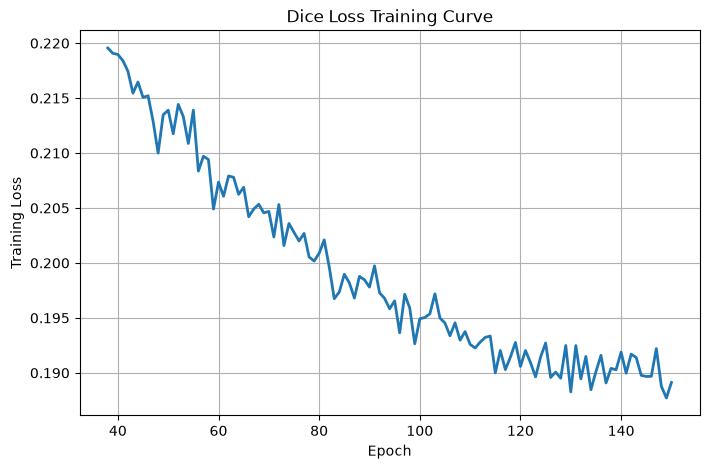

In [30]:
import matplotlib.pyplot as plt

train_losses = np.load("results/dice_train_losses.npy")

epochs = np.arange(38,151)

plt.figure(figsize=(8,5))

plt.plot(
    epochs,
    train_losses,
    linewidth=2
)

plt.title("Dice Loss Training Curve")

plt.xlabel("Epoch")

plt.ylabel("Training Loss")

plt.grid(True)

plt.savefig(
    "results/dice_training_loss_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

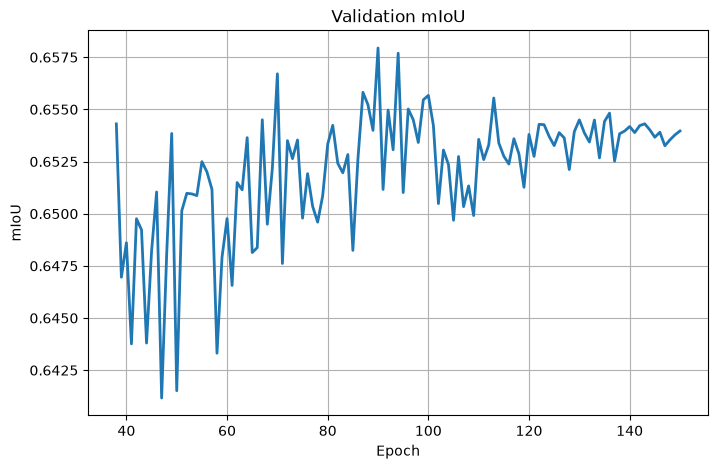

In [31]:
val_miou = np.load("results/dice_val_miou.npy")

epochs = np.arange(38,151)

plt.figure(figsize=(8,5))

plt.plot(
    epochs,
    val_miou,
    linewidth=2
)

plt.title("Validation mIoU")

plt.xlabel("Epoch")

plt.ylabel("mIoU")

plt.grid(True)

plt.savefig(
    "results/dice_validation_miou_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

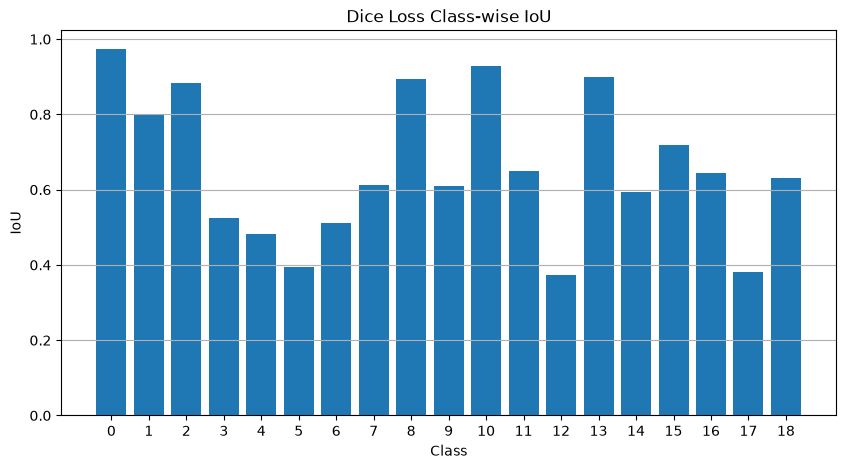

In [32]:
plt.figure(figsize=(10,5))

plt.bar(
    np.arange(19),
    ious
)

plt.xticks(np.arange(19))

plt.xlabel("Class")

plt.ylabel("IoU")

plt.title("Dice Loss Class-wise IoU")

plt.grid(axis="y")

plt.savefig(
    "results/dice_classwise_iou_bar_chart.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

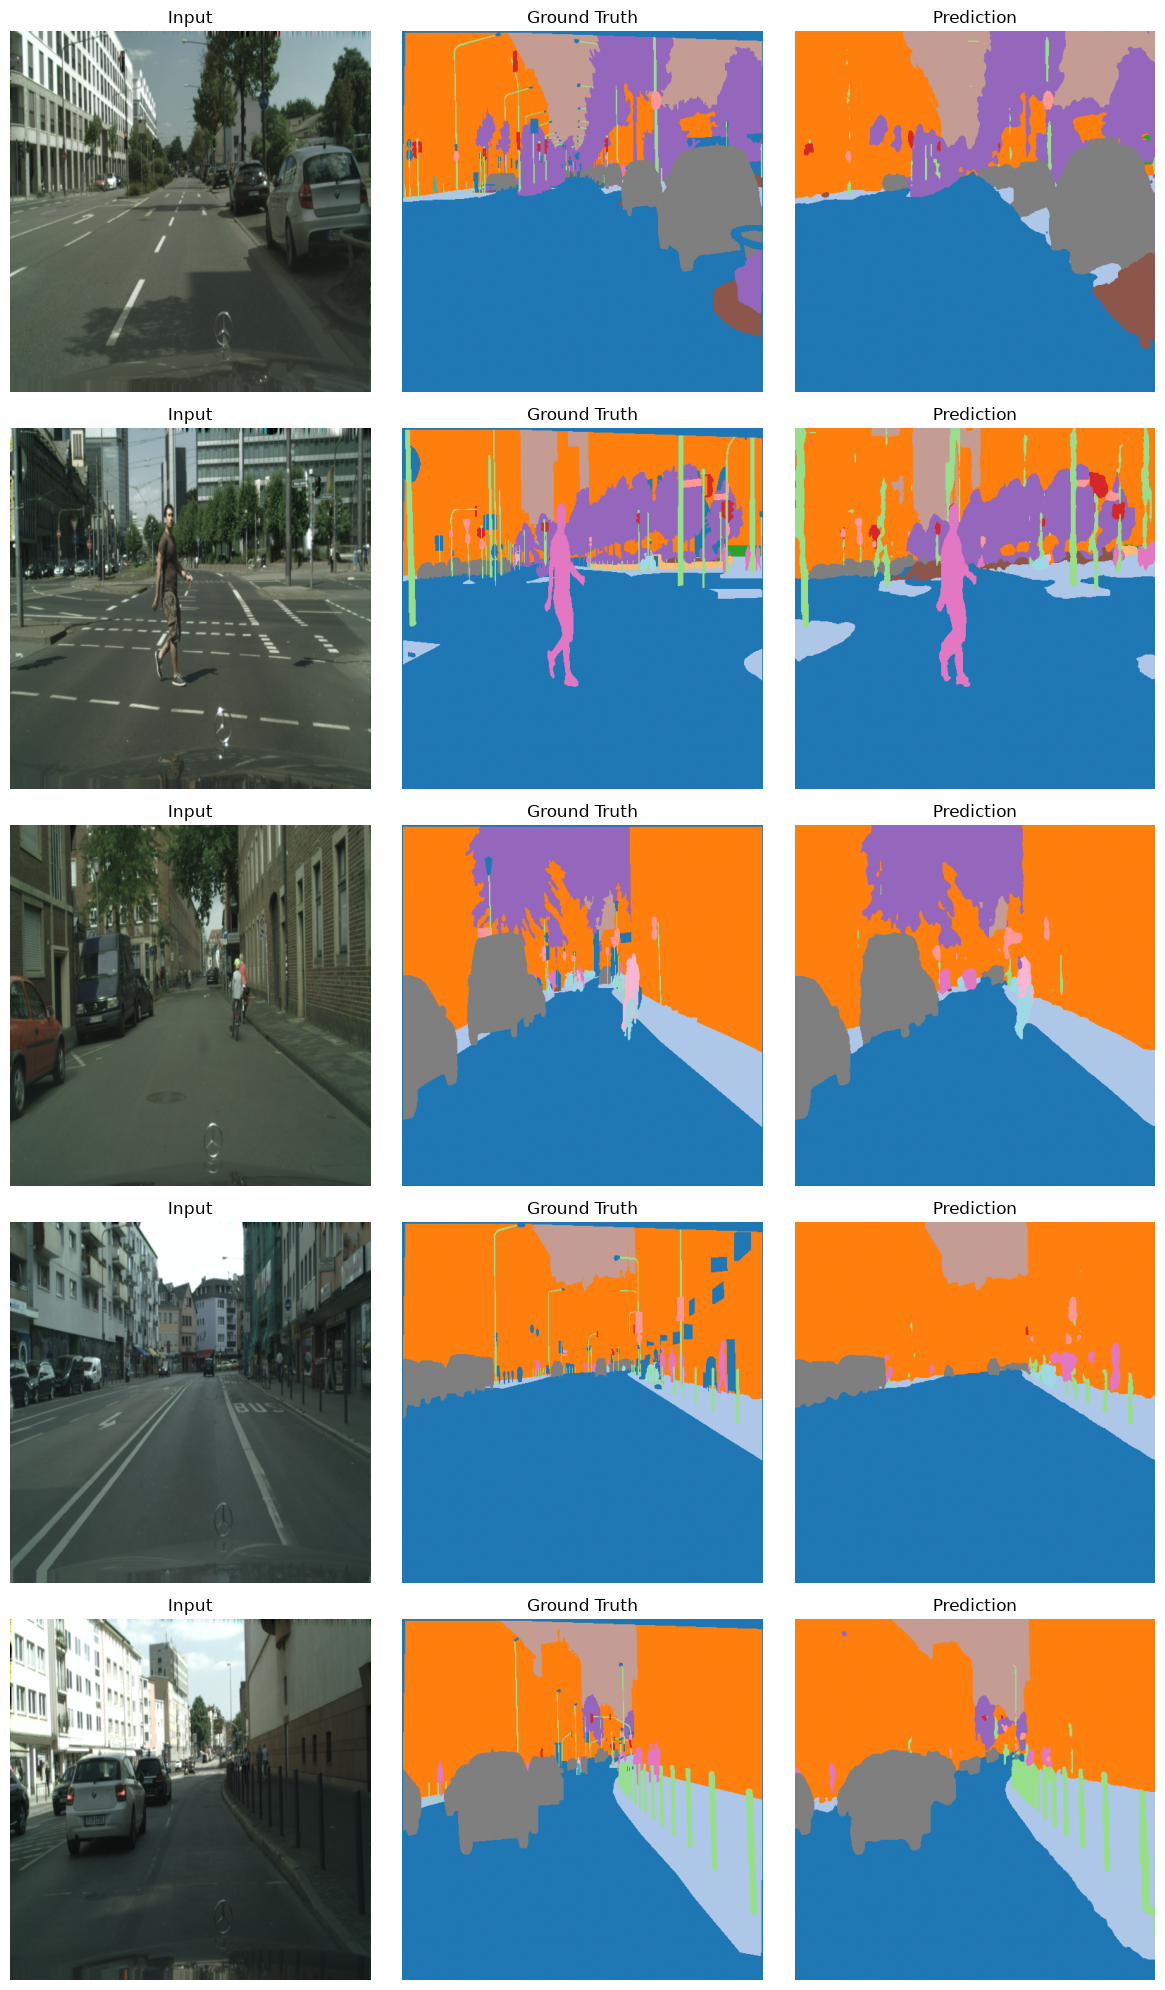

In [35]:
import random
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F

model.eval()

mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

num_images = 5

indices = random.sample(
    range(len(val_dataset)),
    num_images
)

fig, axes = plt.subplots(
    num_images,
    3,
    figsize=(12, 4 * num_images)
)

cmap = "tab20"

with torch.no_grad():

    for row, idx in enumerate(indices):

        image, mask = val_dataset[idx]

        output = model(
            pixel_values=image.unsqueeze(0).to(device)
        )

        logits = F.interpolate(
            output.logits,
            size=(512, 512),
            mode="bilinear",
            align_corners=False
        )

        pred = torch.argmax(
            logits,
            dim=1
        ).squeeze().cpu().numpy().astype(np.uint8)

        img = image.permute(1, 2, 0).cpu().numpy()

        img = img * std + mean
        img = np.clip(img, 0, 1)

        gt = mask.squeeze().cpu().numpy().astype(np.uint8)

        # Ignore pixels (255) ko black dikhao
        gt = gt.copy()
        gt[gt == 255] = 0

        axes[row, 0].imshow(img)
        axes[row, 0].set_title("Input")

        axes[row, 1].imshow(
            gt,
            cmap=cmap,
            vmin=0,
            vmax=18
        )
        axes[row, 1].set_title("Ground Truth")

        axes[row, 2].imshow(
            pred,
            cmap=cmap,
            vmin=0,
            vmax=18
        )
        axes[row, 2].set_title("Prediction")

        for col in range(3):
            axes[row, col].axis("off")

plt.tight_layout()

plt.savefig(
    "results/dice_prediction_gallery.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

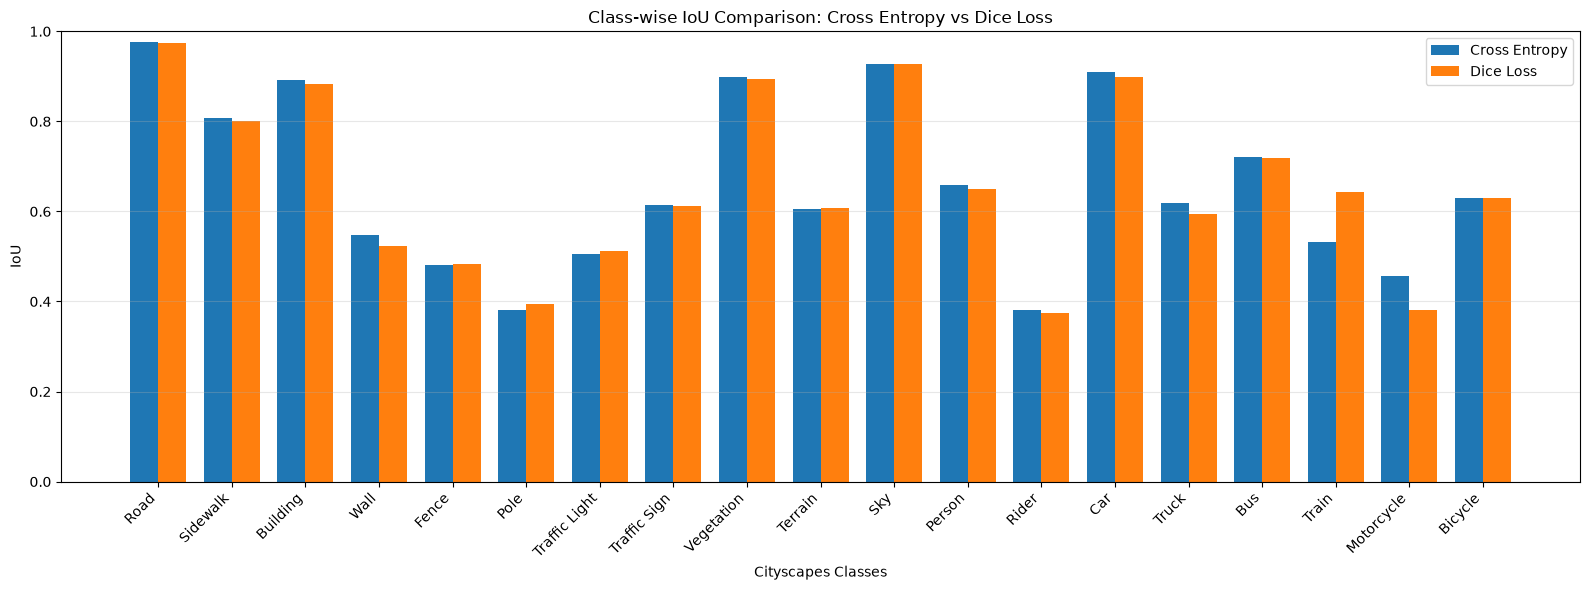

In [7]:
import numpy as np
import matplotlib.pyplot as plt

class_names = [
    "Road","Sidewalk","Building","Wall","Fence",
    "Pole","Traffic Light","Traffic Sign","Vegetation",
    "Terrain","Sky","Person","Rider","Car",
    "Truck","Bus","Train","Motorcycle","Bicycle"
]

ce_iou = [
    0.9762,0.8079,0.8924,0.5467,0.4819,
    0.3819,0.5065,0.6134,0.8976,
    0.6061,0.9274,0.6590,0.3819,
    0.9097,0.6184,0.7210,0.5331,
    0.4574,0.6295
]

dice_iou = [
    0.9742,0.8000,0.8838,0.5243,0.4827,
    0.3934,0.5115,0.6126,0.8932,
    0.6086,0.9276,0.6499,0.3735,
    0.8986,0.5934,0.7184,0.6439,
    0.3807,0.6306
]

x = np.arange(len(class_names))
width = 0.38

plt.figure(figsize=(16,6))

plt.bar(
    x - width/2,
    ce_iou,
    width,
    label="Cross Entropy"
)

plt.bar(
    x + width/2,
    dice_iou,
    width,
    label="Dice Loss"
)

plt.xticks(
    x,
    class_names,
    rotation=45,
    ha="right"
)

plt.xlabel("Cityscapes Classes")
plt.ylabel("IoU")
plt.title("Class-wise IoU Comparison: Cross Entropy vs Dice Loss")

plt.ylim(0,1)

plt.grid(axis="y", alpha=0.3)

plt.legend()

plt.tight_layout()

plt.savefig(
    "results/classwise_ce_vs_dice_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [13]:
ce_miou = 0.660414
dice_miou = 0.657942

print("="*80)
print("CLASS-WISE PERFORMANCE ANALYSIS")
print("="*80)

ce_better = 0
dice_better = 0

for name, ce, dice in zip(class_names, ce_iou, dice_iou):

    if ce > dice:
        ce_better += 1
        print(f"{name:<18}: Cross Entropy performed better "
              f"({ce:.4f} vs {dice:.4f})")

    elif dice > ce:
        dice_better += 1
        print(f"{name:<18}: Dice Loss performed better "
              f"({dice:.4f} vs {ce:.4f})")

print("\n" + "="*80)
print("OVERALL COMPARISON")
print("="*80)

print(f"Cross Entropy mIoU : {ce_miou:.6f}")
print(f"Dice Loss mIoU     : {dice_miou:.6f}")

print("\nClasses better with Cross Entropy :", ce_better)
print("Classes better with Dice Loss     :", dice_better)

if ce_miou > dice_miou:

    print("\nConclusion:")
    print(
        "Cross Entropy achieved a slightly higher overall "
        "mIoU than Dice Loss on the Cityscapes dataset."
    )

else:

    print("\nConclusion:")
    print(
        "Dice Loss achieved a slightly higher overall "
        "mIoU than Cross Entropy on the Cityscapes dataset."
    )

print("="*80)

CLASS-WISE PERFORMANCE ANALYSIS
Road              : Cross Entropy performed better (0.9762 vs 0.9742)
Sidewalk          : Cross Entropy performed better (0.8079 vs 0.8000)
Building          : Cross Entropy performed better (0.8924 vs 0.8838)
Wall              : Cross Entropy performed better (0.5467 vs 0.5243)
Fence             : Dice Loss performed better (0.4827 vs 0.4819)
Pole              : Dice Loss performed better (0.3934 vs 0.3819)
Traffic Light     : Dice Loss performed better (0.5115 vs 0.5065)
Traffic Sign      : Cross Entropy performed better (0.6134 vs 0.6126)
Vegetation        : Cross Entropy performed better (0.8976 vs 0.8932)
Terrain           : Dice Loss performed better (0.6086 vs 0.6061)
Sky               : Dice Loss performed better (0.9276 vs 0.9274)
Person            : Cross Entropy performed better (0.6590 vs 0.6499)
Rider             : Cross Entropy performed better (0.3819 vs 0.3735)
Car               : Cross Entropy performed better (0.9097 vs 0.8986)
Truck   

In [11]:
class_names = [
    "Road","Sidewalk","Building","Wall","Fence",
    "Pole","Traffic Light","Traffic Sign","Vegetation",
    "Terrain","Sky","Person","Rider","Car",
    "Truck","Bus","Train","Motorcycle","Bicycle"
]

ce_iou = [
    0.9762,0.8079,0.8924,0.5467,0.4819,
    0.3819,0.5065,0.6134,0.8976,
    0.6061,0.9274,0.6590,0.3819,
    0.9097,0.6184,0.7210,0.5331,
    0.4574,0.6295
]

dice_iou = [
    0.9742,0.8000,0.8838,0.5243,0.4827,
    0.3934,0.5115,0.6126,0.8932,
    0.6086,0.9276,0.6499,0.3735,
    0.8986,0.5934,0.7184,0.6439,
    0.3807,0.6306
]

print("-"*90)
print(f"{'Class':<18}{'Cross Entropy':<20}{'Dice Loss':<15}{'Better Performance'}")
print("-"*90)

for cls, ce, dice in zip(class_names, ce_iou, dice_iou):

    better = "Cross Entropy" if ce > dice else "Dice Loss"

    print(f"{cls:<18}{ce:<20.4f}{dice:<15.4f}{better}")

print("-"*90)

------------------------------------------------------------------------------------------
Class             Cross Entropy       Dice Loss      Better Performance
------------------------------------------------------------------------------------------
Road              0.9762              0.9742         Cross Entropy
Sidewalk          0.8079              0.8000         Cross Entropy
Building          0.8924              0.8838         Cross Entropy
Wall              0.5467              0.5243         Cross Entropy
Fence             0.4819              0.4827         Dice Loss
Pole              0.3819              0.3934         Dice Loss
Traffic Light     0.5065              0.5115         Dice Loss
Traffic Sign      0.6134              0.6126         Cross Entropy
Vegetation        0.8976              0.8932         Cross Entropy
Terrain           0.6061              0.6086         Dice Loss
Sky               0.9274              0.9276         Dice Loss
Person            0.6590     

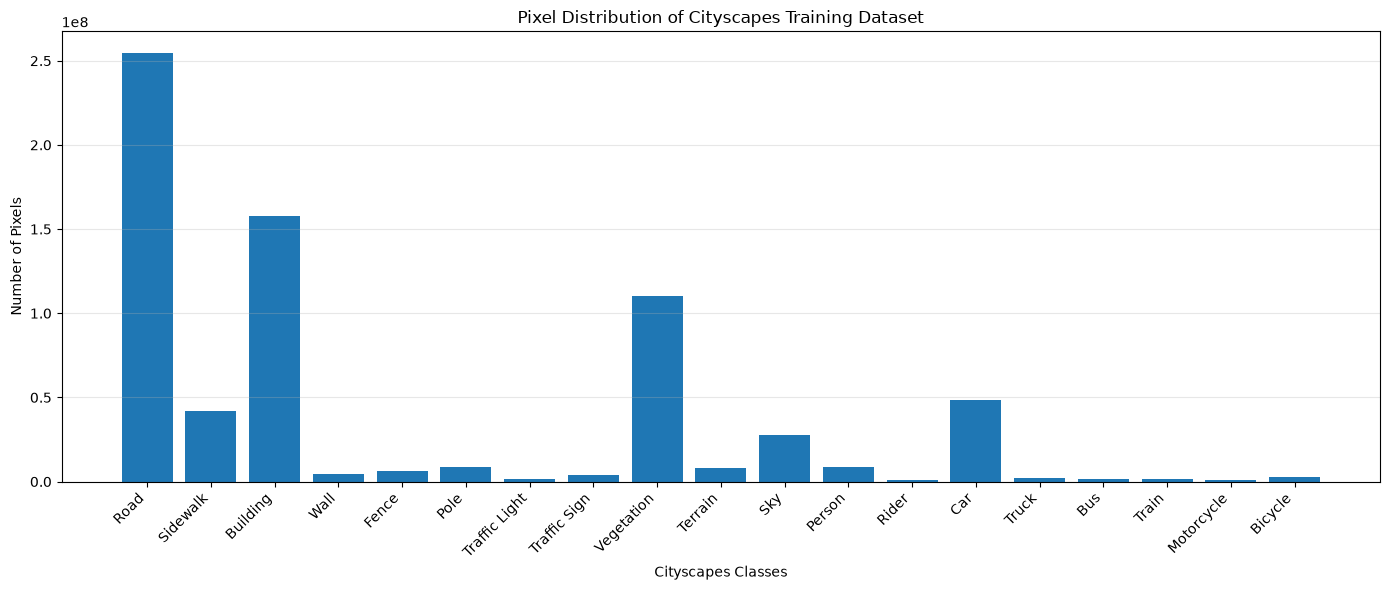

In [12]:
import numpy as np
import matplotlib.pyplot as plt

num_classes = 19

class_names = [
    "Road","Sidewalk","Building","Wall","Fence",
    "Pole","Traffic Light","Traffic Sign","Vegetation",
    "Terrain","Sky","Person","Rider","Car",
    "Truck","Bus","Train","Motorcycle","Bicycle"
]

pixel_counts = np.zeros(num_classes, dtype=np.int64)

for _, masks in train_loader:

    masks = masks.squeeze(1).numpy()

    for cls in range(num_classes):

        pixel_counts[cls] += np.sum(masks == cls)

plt.figure(figsize=(14,6))

plt.bar(class_names, pixel_counts)

plt.xticks(rotation=45, ha="right")

plt.xlabel("Cityscapes Classes")

plt.ylabel("Number of Pixels")

plt.title("Pixel Distribution of Cityscapes Training Dataset")

plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    "results/pixel_distribution_bar_chart.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()